<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/01_baca_tampil_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [18]:

import os

DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

kelas_list = ["TAS", "BUKU GAMBAR", "LAPTOP"]
kondisi_list = ["KONDISI IDEAL", "KONDISI SULIT"]

total_foto = 0

print("=" * 45)
print("LAPORAN PEMERIKSAAN DATASET CNN")
print("=" * 45)

for kelas in kelas_list:
    for kondisi in kondisi_list:

        folder = os.path.join(DATASET_DIR, kelas, kondisi)

        foto = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        jumlah = len(foto)
        total_foto += jumlah

        print(f"{kelas}/{kondisi}: {jumlah} foto")

print("-" * 45)
print("TOTAL SELURUH FOTO:", total_foto)
print("=" * 45)


LAPORAN PEMERIKSAAN DATASET CNN
TAS/KONDISI IDEAL: 20 foto
TAS/KONDISI SULIT: 20 foto
BUKU GAMBAR/KONDISI IDEAL: 20 foto
BUKU GAMBAR/KONDISI SULIT: 20 foto
LAPTOP/KONDISI IDEAL: 20 foto
LAPTOP/KONDISI SULIT: 20 foto
---------------------------------------------
TOTAL SELURUH FOTO: 120


In [19]:

import os
from PIL import Image
import matplotlib.pyplot as plt

kelas_list = ["TAS", "BUKU GAMBAR", "LAPTOP"]
kondisi_list = ["KONDISI IDEAL", "KONDISI SULIT"]

berhasil = 0
rusak = []

print("PEMERIKSAAN KUALITAS GAMBAR")
print("=" * 45)

for kelas in kelas_list:
    for kondisi in kondisi_list:

        folder = os.path.join(DATASET_DIR, kelas, kondisi)

        for nama_file in os.listdir(folder):
            if nama_file.lower().endswith((".jpg", ".jpeg", ".png")):
                path = os.path.join(folder, nama_file)

                try:
                    with Image.open(path) as img:
                        img.verify()
                    berhasil += 1

                except Exception:
                    rusak.append(path)

print("Total gambar diperiksa :", berhasil + len(rusak))
print("Gambar berhasil dibaca :", berhasil)
print("Gambar rusak           :", len(rusak))

if len(rusak) == 0:
    print("\nSEMUA GAMBAR BERHASIL DIPERIKSA!")
else:
    print("\nDAFTAR GAMBAR RUSAK:")
    for file in rusak:
        print(file)


PEMERIKSAAN KUALITAS GAMBAR
Total gambar diperiksa : 120
Gambar berhasil dibaca : 120
Gambar rusak           : 0

SEMUA GAMBAR BERHASIL DIPERIKSA!


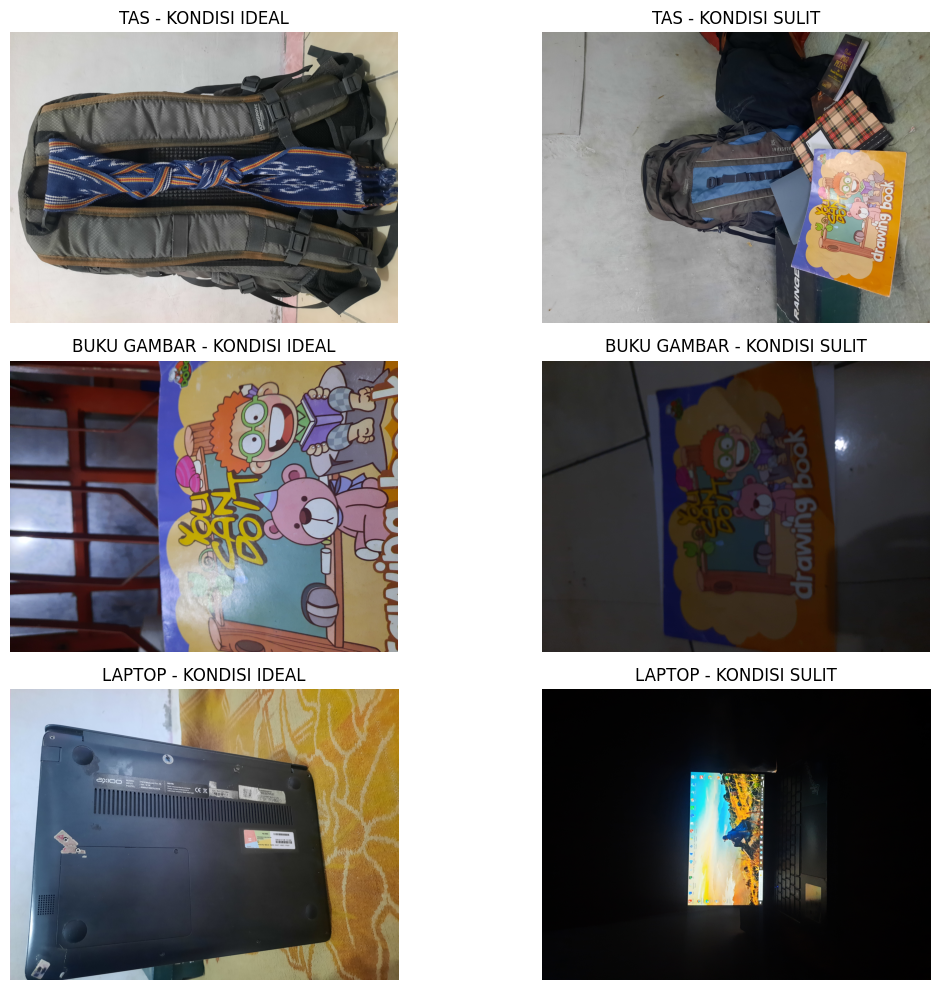

In [20]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

kelas_list = ["TAS", "BUKU GAMBAR", "LAPTOP"]
kondisi_list = ["KONDISI IDEAL", "KONDISI SULIT"]

plt.figure(figsize=(12, 10))

posisi = 1

for kelas in kelas_list:
    for kondisi in kondisi_list:

        folder = os.path.join(DATASET_DIR, kelas, kondisi)

        foto = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        nama_foto = random.choice(foto)
        path = os.path.join(folder, nama_foto)

        gambar = Image.open(path).convert("RGB")

        plt.subplot(3, 2, posisi)
        plt.imshow(gambar)
        plt.title(f"{kelas} - {kondisi}")
        plt.axis("off")

        posisi += 1

plt.tight_layout()
plt.show()
